<a href="https://colab.research.google.com/github/reshmiee/codemixing_llmrouter/blob/main/RouteLLMBERTComparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: mount Drive and install
from google.colab import drive
drive.mount('/content/drive')
!pip install -q huggingface_hub pandas

Mounted at /content/drive


In [2]:
# Cell 2: download RouterBench's released data
from huggingface_hub import snapshot_download
path = snapshot_download(repo_id="withmartian/routerbench", repo_type="dataset")
import os
print(path, os.listdir(path))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

/root/.cache/huggingface/hub/datasets--withmartian--routerbench/snapshots/784021482c3f320c6619ed4b3bb3b41a21424fcb ['routerbench_raw.pkl', '.gitattributes', 'README.md', 'routerbench_0shot.pkl', 'routerbench_5shot.pkl']


In [3]:
# Cell 3: load the 0-shot file and look at it
import pandas as pd, glob
f = glob.glob(path + "/*0shot*.pkl")[0]
df = pd.read_pickle(f)
print(df.shape)
print(list(df.columns))
print(df['eval_name'].value_counts())

(36497, 37)
['sample_id', 'prompt', 'eval_name', 'WizardLM/WizardLM-13B-V1.2', 'claude-instant-v1', 'claude-v1', 'claude-v2', 'gpt-3.5-turbo-1106', 'gpt-4-1106-preview', 'meta/code-llama-instruct-34b-chat', 'meta/llama-2-70b-chat', 'mistralai/mistral-7b-chat', 'mistralai/mixtral-8x7b-chat', 'zero-one-ai/Yi-34B-Chat', 'gpt-3.5-turbo-1106|model_response', 'claude-instant-v1|model_response', 'claude-v1|model_response', 'claude-v2|model_response', 'gpt-4-1106-preview|model_response', 'meta/llama-2-70b-chat|model_response', 'mistralai/mixtral-8x7b-chat|model_response', 'zero-one-ai/Yi-34B-Chat|model_response', 'WizardLM/WizardLM-13B-V1.2|model_response', 'meta/code-llama-instruct-34b-chat|model_response', 'mistralai/mistral-7b-chat|model_response', 'gpt-3.5-turbo-1106|total_cost', 'claude-instant-v1|total_cost', 'claude-v1|total_cost', 'claude-v2|total_cost', 'gpt-4-1106-preview|total_cost', 'meta/llama-2-70b-chat|total_cost', 'mistralai/mixtral-8x7b-chat|total_cost', 'zero-one-ai/Yi-34B-Ch

In [4]:
# Cell 4: keep only what we need
keep = ['sample_id', 'prompt', 'eval_name',
        'gpt-4-1106-preview', 'mistralai/mixtral-8x7b-chat',
        'gpt-4-1106-preview|total_cost', 'mistralai/mixtral-8x7b-chat|total_cost']
small = df[keep].copy()
small.columns = ['sample_id', 'prompt', 'dataset',
                 'score_strong', 'score_weak', 'cost_strong', 'cost_weak']

# Cell 5: sanity checks
print(small[['score_strong', 'score_weak', 'cost_strong', 'cost_weak']].describe())
print(small.isna().sum())
for name in ['grade-school-math', 'arc-challenge']:
    sub = small[small.dataset == name]
    print(name, len(sub),
          'strong acc', round(sub.score_strong.mean(), 3),
          'weak acc', round(sub.score_weak.mean(), 3),
          'strong cost', round(sub.cost_strong.sum(), 2),
          'weak cost', round(sub.cost_weak.sum(), 2))
    print(repr(sub.prompt.iloc[0][:600]))
    print('unique scores:', sorted(sub.score_strong.dropna().unique())[:10])

        cost_strong     cost_weak
count  36497.000000  36497.000000
mean       0.003293      0.000135
std        0.003429      0.000088
min        0.000170      0.000011
25%        0.001010      0.000060
50%        0.001930      0.000113
75%        0.003740      0.000185
max        0.050730      0.001655
sample_id       0
prompt          0
dataset         0
score_strong    0
score_weak      0
cost_strong     0
cost_weak       0
dtype: int64
grade-school-math 7450 strong acc 0.659 weak acc 0.519 strong cost 63.68 weak cost 1.97
"['TASK: Solve the following grade school math problem and provide a numerical answer.\\nThe following are examples of grade school math problems and answers:\\nQuestion: There are 15 trees in the grove. Grove workers will plant trees in the grove today. After they are done, there will be 21 trees. How many trees did the grove workers plant today? \\nAnswer: 6\\n\\nQuestion: If there are 3 cars in the parking lot and 2 more cars arrive, how many cars are in the p

In [5]:
# Cell 6: save the cleaned file inside MyDrive/MLResearch
import os
folder = '/content/drive/MyDrive/MLResearch'
os.makedirs(folder, exist_ok=True)

chosen = small[small.dataset.isin(['grade-school-math', 'arc-challenge'])].dropna().reset_index(drop=True)
chosen.to_csv(f'{folder}/routerbench_clean.csv', index=False)
print(chosen.shape)
print(chosen.dataset.value_counts())
print(os.listdir(folder))

(8920, 7)
dataset
grade-school-math    7450
arc-challenge        1470
Name: count, dtype: int64
['routerbench_clean.csv']


In [6]:
# Cell 7: first look at the end of the GSM8K prompts (check before cleaning)
g = chosen[chosen.dataset == 'grade-school-math']
for i in [0, 1, 2]:
    print(repr(g.prompt.iloc[i][-350:]))
    print('---')

"any lollipops did Jason give to Denny?\\nAnswer: 8\\n\\nQuestion: Shawn has five toys. For Christmas, he got two toys each from his mom and dad. How many toys does he have now? \\nAnswer: 9\\n\\n', 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?']"
---
"llipops. Now Jason has 12 lollipops. How many lollipops did Jason give to Denny?\\nAnswer: 8\\n\\nQuestion: Shawn has five toys. For Christmas, he got two toys each from his mom and dad. How many toys does he have now? \\nAnswer: 9\\n\\n', 'Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?']"
---
"r: 9\\n\\n', 'A deep-sea monster rises from the waters once every hundred years to feast on a ship and sate its hunger. Over three hundred years, it has consumed 847 people. Ships have been built larger over time, so each new ship has twice as many people as the last ship.

In [7]:
# Cell 8: extract just the question
import re

def extract_question(prompt, dataset):
    p = prompt.strip()
    if p.startswith("['") or p.startswith('["'):
        p = p[2:]
    if p.endswith("']") or p.endswith('"]'):
        p = p[:-2]
    p = p.replace('\\n', '\n')
    if dataset == 'grade-school-math':
        q = p.split('Question:')[-1]
        q = re.split(r'\nAnswer:', q)[0]
        return q.strip()
    else:  # arc-challenge
        q = p.split('Print only a single choice')[0]
        return q.strip()

chosen['question'] = [extract_question(p, d) for p, d in zip(chosen.prompt, chosen.dataset)]
for d in ['grade-school-math', 'arc-challenge']:
    print(d)
    for q in chosen[chosen.dataset == d].question.iloc[:3]:
        print(repr(q[:300]))
print(chosen.question.str.len().describe())

grade-school-math
'Shawn has five toys. For Christmas, he got two toys each from his mom and dad. How many toys does he have now?'
'Shawn has five toys. For Christmas, he got two toys each from his mom and dad. How many toys does he have now?'
'Shawn has five toys. For Christmas, he got two toys each from his mom and dad. How many toys does he have now?'
arc-challenge
'An astronomer observes that a planet rotates faster after a meteorite impact. Which is the most likely effect of this increase in rotation?\nA) Planetary years will become longer.\nB) Planetary gravity will become stronger.\nC) Planetary days will become shorter.\nD) Planetary density will decrease.'
'A group of engineers wanted to know how different building designs would respond during an earthquake. They made several models of buildings and tested each for its ability to withstand earthquake conditions. Which will most likely result from testing different building designs?\nA) buildings will be'
'According to cell cla

In [9]:
# Cell 8 (replacement): parse the stored list and take the last element
import ast

def extract_question(prompt, dataset):
    try:
        parts = ast.literal_eval(prompt)
        p = parts[-1] if isinstance(parts, (list, tuple)) else str(parts)
    except Exception:
        p = prompt.strip().strip("[]").strip("'\"")
        p = p.replace('\\n', '\n')
    if dataset == 'arc-challenge':
        p = p.split('Print only a single choice')[0]
    return p.strip()

chosen['question'] = [extract_question(p, d) for p, d in zip(chosen.prompt, chosen.dataset)]

for d in ['grade-school-math', 'arc-challenge']:
    sub = chosen[chosen.dataset == d]
    print(d, 'unique questions:', sub.question.nunique(), 'of', len(sub))
    for q in sub.question.iloc[:3]:
        print(repr(q[:250]))
print(chosen.question.str.len().describe())

grade-school-math unique questions: 7450 of 7450
'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?'
'Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?'
'A deep-sea monster rises from the waters once every hundred years to feast on a ship and sate its hunger. Over three hundred years, it has consumed 847 people. Ships have been built larger over time, so each new ship has twice as many people as the l'
arc-challenge unique questions: 1470 of 1470
'An astronomer observes that a planet rotates faster after a meteorite impact. Which is the most likely effect of this increase in rotation?\nA) Planetary years will become longer.\nB) Planetary gravity will become stronger.\nC) Planetary days will becom'
'A group of engineers wanted to know how different building designs would respond during an earthquake. They made several m

In [10]:
# Cell 9a: install without the serve/eval extras
!pip install -q routellm

In [12]:
import os, pandas as pd
from tqdm import tqdm

folder = '/content/drive/MyDrive/MLResearch'
part_path = f'{folder}/bert_scores_partial.csv'

# resume if a partial file exists
done = pd.read_csv(part_path) if os.path.exists(part_path) else pd.DataFrame(columns=['row', 'bert_score'])
scores = dict(zip(done.row, done.bert_score))
print('already scored:', len(scores))

todo = [i for i in range(len(chosen)) if i not in scores]
for n, i in enumerate(tqdm(todo)):
    scores[i] = bert.calculate_strong_win_rate(chosen.question.iloc[i])
    if (n + 1) % 500 == 0:
        pd.DataFrame({'row': list(scores.keys()), 'bert_score': list(scores.values())}).to_csv(part_path, index=False)

pd.DataFrame({'row': list(scores.keys()), 'bert_score': list(scores.values())}).to_csv(part_path, index=False)
chosen['bert_score'] = [scores[i] for i in range(len(chosen))]
chosen.to_csv(f'{folder}/routerbench_scored.csv', index=False)
print(chosen.groupby('dataset').bert_score.describe())

already scored: 0


  1%|▏         | 128/8920 [00:48<55:47,  2.63it/s]


KeyboardInterrupt: 

In [13]:
import torch
print(torch.cuda.is_available())

False


In [14]:
# Cell A: mount Drive, install, check the GPU
from google.colab import drive
drive.mount('/content/drive')
!pip install -q routellm huggingface_hub pandas
import torch
print('GPU available:', torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: False


In [15]:
# Cell B: load the cleaned file and rebuild the questions
import pandas as pd, ast

folder = '/content/drive/MyDrive/MLResearch'
chosen = pd.read_csv(f'{folder}/routerbench_clean.csv')

def extract_question(prompt, dataset):
    try:
        parts = ast.literal_eval(prompt)
        p = parts[-1] if isinstance(parts, (list, tuple)) else str(parts)
    except Exception:
        p = prompt.strip().strip("[]").strip("'\"").replace('\\n', '\n')
    if dataset == 'arc-challenge':
        p = p.split('Print only a single choice')[0]
    return p.strip()

chosen['question'] = [extract_question(p, d) for p, d in zip(chosen.prompt, chosen.dataset)]
print(chosen.shape, chosen.question.nunique())

(8920, 8) 8920


In [19]:
!nvidia-smi
import torch
print(torch.cuda.is_available())

/bin/bash: line 1: nvidia-smi: command not found
False


In [21]:
import os, time
import pandas as pd
from tqdm import tqdm

folder = '/content/drive/MyDrive/MLResearch'

# fixed-seed random sample: 600 GSM8K + 400 ARC (change the numbers if you want more or less)
sample = pd.concat([
    chosen[chosen.dataset == 'grade-school-math'].sample(300, random_state=42),
    chosen[chosen.dataset == 'arc-challenge'].sample(200, random_state=42),
]).sort_index()

part_path = f'{folder}/bert_scores_sample_partial.csv'
done = pd.read_csv(part_path) if os.path.exists(part_path) else pd.DataFrame(columns=['row', 'bert_score'])
scores = dict(zip(done.row, done.bert_score))

todo = [i for i in sample.index if i not in scores]
for n, i in enumerate(tqdm(todo)):
    scores[i] = bert.calculate_strong_win_rate(chosen.question.loc[i])
    if (n + 1) % 100 == 0:
        pd.DataFrame({'row': list(scores.keys()), 'bert_score': list(scores.values())}).to_csv(part_path, index=False)

pd.DataFrame({'row': list(scores.keys()), 'bert_score': list(scores.values())}).to_csv(part_path, index=False)
sample['bert_score'] = [scores[i] for i in sample.index]
sample.to_csv(f'{folder}/routerbench_scored_sample.csv', index=False)
print(len(sample))
print(sample.groupby('dataset').bert_score.describe())

100%|██████████| 442/442 [02:37<00:00,  2.80it/s]

500
                   count      mean       std       min       25%       50%  \
dataset                                                                      
arc-challenge      200.0  0.397309  0.121496  0.144285  0.317428  0.371284   
grade-school-math  300.0  0.525258  0.085623  0.269860  0.468462  0.522497   

                        75%       max  
dataset                                
arc-challenge      0.434454  0.832818  
grade-school-math  0.574441  0.806782  


In [22]:
import numpy as np, pandas as pd
folder = '/content/drive/MyDrive/MLResearch'
df = pd.read_csv(f'{folder}/routerbench_scored_sample.csv').reset_index(drop=True)

S, W = df.score_strong.values, df.score_weak.values
CS, CW = df.cost_strong.values, df.cost_weak.values
sc = df.bert_score.values
n = len(df)

def run(idx, share):
    """route the top `share` of prompts (by BERT score) to the strong model"""
    s, w, cs, cw, b = S[idx], W[idx], CS[idx], CW[idx], sc[idx]
    k = int(round(share * len(idx)))
    order = np.argsort(-b)
    to_strong = np.zeros(len(idx), bool); to_strong[order[:k]] = True
    acc = np.where(to_strong, s, w).mean()
    cost = np.where(to_strong, cs, cw).sum()
    return acc, cost, to_strong

def random_expect(idx, share):
    s, w, cs, cw = S[idx], W[idx], CS[idx], CW[idx]
    return share*s.mean() + (1-share)*w.mean(), share*cs.sum() + (1-share)*cw.sum()

def saved_at_matching_acc(idx, acc_r, cost_r):
    """cost of randomly mixing strong/weak to reach the router's accuracy, minus router cost"""
    a_s, a_w = S[idx].mean(), W[idx].mean()
    q = np.clip((acc_r - a_w) / (a_s - a_w), 0, 1)
    c_rand = q*CS[idx].sum() + (1-q)*CW[idx].sum()
    return c_rand - cost_r, c_rand

allidx = np.arange(n)
shares = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
rows = []
for sh in shares:
    acc, cost, ts = run(allidx, sh)
    racc, rcost = random_expect(allidx, sh)
    saved, c_rand = saved_at_matching_acc(allidx, acc, cost)
    thr = np.sort(sc)[::-1][int(round(sh*n))-1]          # cut-off score on OUR prompts
    rows.append(dict(target_share=sh, cutoff_score=round(thr,5),
        actual_share=ts.mean().round(3),
        share_gsm8k=ts[(df.dataset=='grade-school-math').values].mean().round(3),
        share_arc=ts[(df.dataset=='arc-challenge').values].mean().round(3),
        router_acc=acc, router_cost=cost, random_acc=racc, random_cost=rcost,
        acc_gain_vs_random=acc-racc, cost_saved_at_matching_acc=saved,
        pct_saved=100*saved/c_rand))

# bootstrap 95% CI for accuracy gain over random routing and for cost saved
rng = np.random.default_rng(42)
B = 2000
boot = {sh: {'gain': [], 'saved': []} for sh in shares}
for _ in range(B):
    idx = rng.integers(0, n, n)
    for sh in shares:
        acc, cost, _ = run(idx, sh)
        racc, _ = random_expect(idx, sh)
        sv, _ = saved_at_matching_acc(idx, acc, cost)
        boot[sh]['gain'].append(acc-racc); boot[sh]['saved'].append(sv)
for r in rows:
    g, s_ = boot[r['target_share']]['gain'], boot[r['target_share']]['saved']
    r['gain_ci_low'], r['gain_ci_high'] = np.percentile(g, [2.5, 97.5])
    r['saved_ci_low'], r['saved_ci_high'] = np.percentile(s_, [2.5, 97.5])

res = pd.DataFrame(rows)
res.to_csv(f'{folder}/results_router_vs_baselines.csv', index=False)

base = pd.DataFrame([
    dict(method='always_strong (GPT-4)', acc=S.mean(), cost=CS.sum()),
    dict(method='always_weak (Mixtral)', acc=W.mean(), cost=CW.sum()),
    dict(method='oracle (cheapest correct)', acc=np.maximum(S, W).mean(),
         cost=np.where(W >= S, CW, CS).sum()),
])
base.to_csv(f'{folder}/results_baselines.csv', index=False)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print(base.round(4))
print(res[['target_share','cutoff_score','actual_share','share_gsm8k','share_arc',
           'router_acc','random_acc','acc_gain_vs_random','gain_ci_low','gain_ci_high']].round(4))
print(res[['target_share','router_cost','random_cost','cost_saved_at_matching_acc',
           'pct_saved','saved_ci_low','saved_ci_high']].round(4))

                      method     acc    cost
0      always_strong (GPT-4)  0.7735  2.6961
1      always_weak (Mixtral)  0.6350  0.0912
2  oracle (cheapest correct)  0.7940  1.1042
   target_share  cutoff_score  actual_share  share_gsm8k  share_arc  router_acc  random_acc  acc_gain_vs_random  gain_ci_low  gain_ci_high
0           0.1        0.6256           0.1        0.120      0.070      0.6460      0.6488             -0.0029      -0.0116        0.0089
1           0.2        0.5734           0.2        0.257      0.115      0.6605      0.6627             -0.0022      -0.0126        0.0107
2           0.3        0.5346           0.3        0.413      0.130      0.6725      0.6766             -0.0040      -0.0174        0.0084
3           0.4        0.5065           0.4        0.573      0.140      0.6840      0.6904             -0.0064      -0.0202        0.0075
4           0.5        0.4740           0.5        0.717      0.175      0.6995      0.7042             -0.0048      -0.0197 

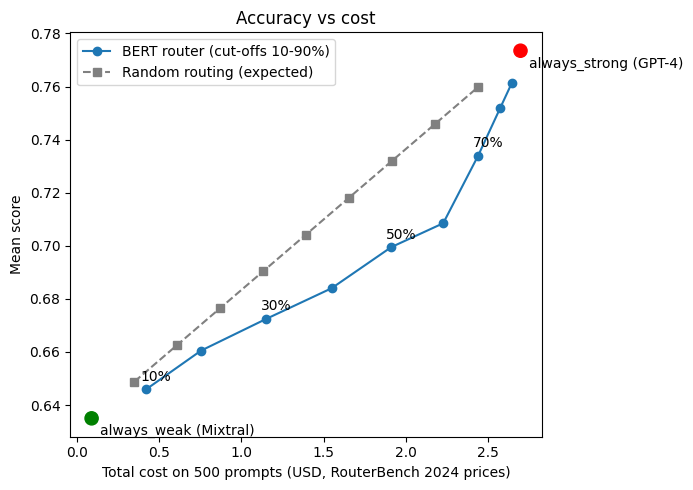

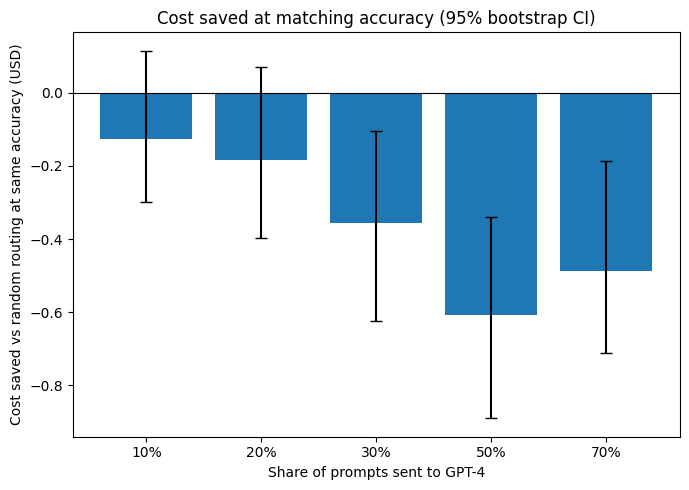

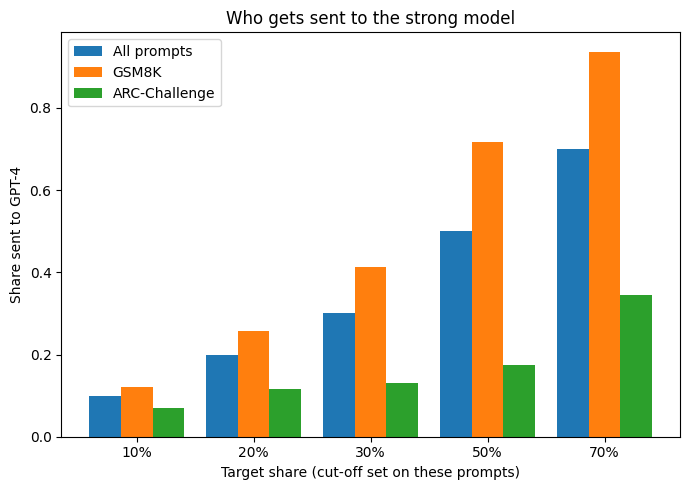

In [23]:
import matplotlib.pyplot as plt

# Chart 1: accuracy vs cost
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(res.router_cost, res.router_acc, 'o-', label='BERT router (cut-offs 10-90%)')
ax.plot(res.random_cost, res.random_acc, 's--', color='gray', label='Random routing (expected)')
ax.scatter(base.cost[:2], base.acc[:2], c=['red','green'], s=90, zorder=5)
for _, r in base.iloc[:2].iterrows(): ax.annotate(r.method, (r.cost, r.acc), textcoords='offset points', xytext=(6,-12))
for _, r in res[res.target_share.isin([.1,.3,.5,.7])].iterrows():
    ax.annotate(f'{int(r.target_share*100)}%', (r.router_cost, r.router_acc), textcoords='offset points', xytext=(-4,6))
ax.set_xlabel('Total cost on 500 prompts (USD, RouterBench 2024 prices)'); ax.set_ylabel('Mean score')
ax.set_title('Accuracy vs cost'); ax.legend(); plt.tight_layout()
plt.savefig(f'{folder}/chart1_accuracy_vs_cost.png', dpi=200); plt.show()

# Chart 2: cost saved at matching accuracy (with 95% CI)
sel = res[res.target_share.isin([.1,.2,.3,.5,.7])]
fig, ax = plt.subplots(figsize=(7,5))
err = [sel.cost_saved_at_matching_acc - sel.saved_ci_low, sel.saved_ci_high - sel.cost_saved_at_matching_acc]
ax.bar([f'{int(s*100)}%' for s in sel.target_share], sel.cost_saved_at_matching_acc, yerr=err, capsize=4)
ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('Share of prompts sent to GPT-4'); ax.set_ylabel('Cost saved vs random routing at same accuracy (USD)')
ax.set_title('Cost saved at matching accuracy (95% bootstrap CI)'); plt.tight_layout()
plt.savefig(f'{folder}/chart2_cost_saved.png', dpi=200); plt.show()

# Chart 3: strong-model share per dataset at each cut-off
fig, ax = plt.subplots(figsize=(7,5))
x = np.arange(len(sel)); w = 0.27
ax.bar(x-w, sel.actual_share, w, label='All prompts')
ax.bar(x, sel.share_gsm8k, w, label='GSM8K')
ax.bar(x+w, sel.share_arc, w, label='ARC-Challenge')
ax.set_xticks(x); ax.set_xticklabels([f'{int(s*100)}%' for s in sel.target_share])
ax.set_xlabel('Target share (cut-off set on these prompts)'); ax.set_ylabel('Share sent to GPT-4')
ax.set_title('Who gets sent to the strong model'); ax.legend(); plt.tight_layout()
plt.savefig(f'{folder}/chart3_strong_share.png', dpi=200); plt.show()

In [24]:
for d in ['grade-school-math', 'arc-challenge']:
    sub = df[df.dataset == d].reset_index(drop=True)
    s, w, b = sub.score_strong.values, sub.score_weak.values, sub.bert_score.values
    order = np.argsort(-b)
    out = []
    for sh in [0.2, 0.5, 0.8]:
        k = int(round(sh * len(sub)))
        ts = np.zeros(len(sub), bool); ts[order[:k]] = True
        rt = np.where(ts, s, w).mean()
        rd = sh * s.mean() + (1 - sh) * w.mean()
        out.append(f'{int(sh*100)}%: router {rt:.3f} vs random {rd:.3f} (diff {rt-rd:+.3f})')
    print(d, len(sub), '|', ' | '.join(out))

grade-school-math 300 | 20%: router 0.557 vs random 0.558 (diff -0.002) | 50%: router 0.595 vs random 0.599 (diff -0.004) | 80%: router 0.627 vs random 0.639 (diff -0.012)
arc-challenge 200 | 20%: router 0.820 vs random 0.819 (diff +0.001) | 50%: router 0.880 vs random 0.863 (diff +0.017) | 80%: router 0.910 vs random 0.906 (diff +0.004)
